In [1]:
import os
import pandas as pd
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
main_folder_path = '/Users/davemag9/VSCode/Mocha/Mochurad Hvoida/Different-Weapon-Types-datasets'
folder_names = [name for name in os.listdir(main_folder_path) if os.path.isdir(os.path.join(main_folder_path, name))]
folder_names.remove('.git')
# folder_names.remove('Grenade')
folder_names.remove('Bazooka')
load_df = pd.DataFrame()
max_num = 0

for name in folder_names:
    folder_path = main_folder_path + f'/{name}'
    image_files = [f for f in os.listdir(folder_path) if f.endswith('.jpg')]
    max_num = max(max_num, len(image_files))


In [3]:
for name in folder_names:
    # Step 1: Get a list of all .jpg files in the folder
    folder_path = main_folder_path + f'/{name}'
    image_files = [f for f in os.listdir(folder_path) if f.endswith('.jpg')]

    # Step 2: Read each image file and convert it into a format that can be stored in a DataFrame
    image_data = []
    for image_file in image_files:
        image_path = os.path.join(folder_path, image_file)
        with Image.open(image_path) as img:
            image_array = img.resize((144, 144))

            image_array = image_array.convert('L')  # Convert image to RGB format
            image_array = image_array.convert("RGB")
            
            image_data.append(image_array)

    while len(image_data) != max_num:
        image_data.append(None)

    # Step 3: Populate the DataFrame with the image data
    load_df[f'{name}'] = image_data

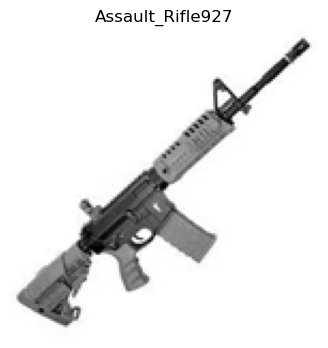

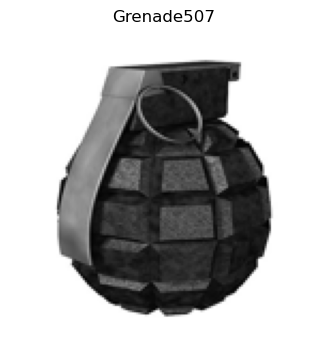

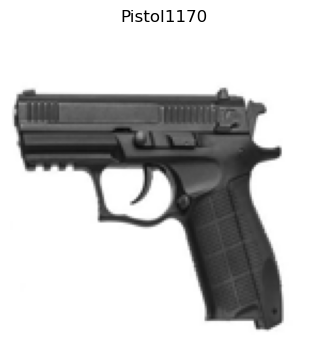

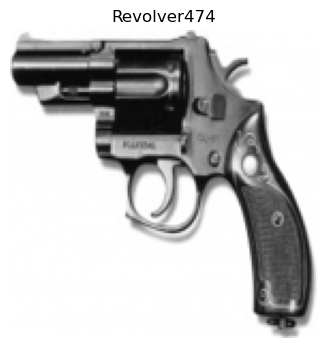

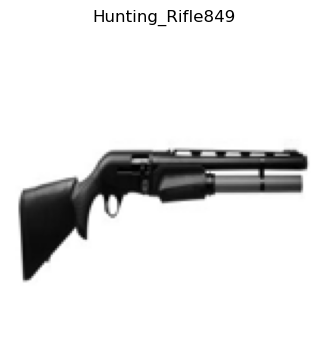

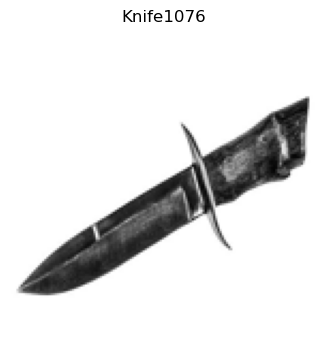

In [4]:
for column_name in folder_names:
    # Get the first image from the column
    first_image = load_df[column_name][0]
    
    plt.figure(figsize=(4, 4))  # Set the figure size
    plt.imshow(first_image)  # Display the image
    plt.title(column_name + str(load_df[column_name].count()))  # Set the title as the column name
    plt.axis('off')  # Turn off axis
    plt.show()  # Show the plot

In [5]:
df = pd.DataFrame()
df['Image'] = load_df.unstack().reset_index(drop=True)
df = df.dropna()
df.reset_index(drop=True, inplace=True)

df.head()

,Image
0,<PIL.Image.Image image mode=RGB size=144x144 a...
1,<PIL.Image.Image image mode=RGB size=144x144 a...
2,<PIL.Image.Image image mode=RGB size=144x144 a...
3,<PIL.Image.Image image mode=RGB size=144x144 a...
4,<PIL.Image.Image image mode=RGB size=144x144 a...


In [6]:
num_not_none = []
for name in folder_names:
    num_not_none.append(load_df[name].count())

max_not_not_none = max(num_not_none)

class_array = []
for i in range(len(folder_names)):
    class_array.append([folder_names[i]] * num_not_none[i])

class_array = np.concatenate(class_array)
df['Class'] = class_array
df = df.sample(frac=1, random_state=42)

In [7]:
pixel_array = []
fpixel_array = []
for elem in df.Image:
    tmp = np.array(elem.convert('L')).flatten()
    fpixel_array.append(tmp)
    subarrays = [tmp[i:i+144] for i in range(0, len(tmp), 144)]
    pixel_array.append(subarrays)

df['Pixel'] = pixel_array
df['FPixel'] = fpixel_array

In [8]:
from sklearn.model_selection import train_test_split

train_percent = 0.95
validation_percent = 0.01
test_percent = 0.04

train_percent = 0.6
validation_percent = 0.2
test_percent = 0.2

# Split the DataFrame into train and (combined) validation sets
train_val_df, test_df = train_test_split(df, test_size=test_percent, random_state=42)

# Calculate the relative percentage of the validation set within the combined validation and test sets
# validation_relative_percent = validation_percent / (validation_percent + test_percent)

# Split the combined validation set into validation and test sets
# validation_df, test_df = train_test_split(test_df, test_size=validation_relative_percent, random_state=42)

# Display the shapes of the resulting DataFrames
train_val_df.reset_index(drop=True, inplace=True)
# validation_df.reset_index(drop=True, inplace=True)
test_df.reset_index(drop=True, inplace=True)
print("Train set shape:", train_val_df.shape)
# print("Validation set shape:", validation_df.shape)
print("Test set shape:", test_df.shape)

Train set shape: (4002, 4)
Test set shape: (1001, 4)


In [9]:
X = train_val_df.Pixel.tolist()
len(X[0][0])

144



In [10]:
plt.figure(figsize=(144,144))
columns = 5
for i in range(5):
    plt.subplot(int(5 / columns + 1), columns, i + 1)
    plt.imshow(X[i],cmap=plt.cm.gray_r,interpolation='nearest')



In [11]:
plt.figure(figsize=(144,144))
columns = 5
for i in range(5):
    plt.subplot(int(5 / columns + 1), columns, i + 1)
    plt.imshow(train_val_df.Image[i],cmap=plt.cm.gray_r,interpolation='nearest')

In [12]:
from sklearn.datasets import load_digits

from sklearn.multiclass import OneVsRestClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn import datasets
from sklearn.metrics import accuracy_score,confusion_matrix # metrics error
from sklearn.model_selection import train_test_split # resampling method

In [13]:
n_jobs = 8  # Use all available cores, or specify the number of cores you want to use

knn = OneVsRestClassifier(KNeighborsClassifier(n_jobs=n_jobs))

In [14]:
X_train = train_val_df.FPixel.tolist()
y_train = train_val_df.Class.tolist()

In [15]:
knn.fit(X_train,y_train)

OneVsRestClassifier(estimator=KNeighborsClassifier(n_jobs=8))

In [26]:
# X_val = validation_df.FPixel.tolist()
# y_val = validation_df.Class.tolist()

X_test = test_df.FPixel.tolist()
y_test = test_df.Class.tolist()
y_test

['Grenade',
 'Knife',
 'Knife',
 'Pistol',
 'Revolver',
 'Assault_Rifle',
 'Pistol',
 'Assault_Rifle',
 'Knife',
 'Pistol',
 'Knife',
 'Assault_Rifle',
 'Pistol',
 'Hunting_Rifle',
 'Knife',
 'Pistol',
 'Assault_Rifle',
 'Assault_Rifle',
 'Pistol',
 'Pistol',
 'Revolver',
 'Hunting_Rifle',
 'Grenade',
 'Grenade',
 'Pistol',
 'Revolver',
 'Hunting_Rifle',
 'Hunting_Rifle',
 'Hunting_Rifle',
 'Hunting_Rifle',
 'Grenade',
 'Pistol',
 'Knife',
 'Assault_Rifle',
 'Knife',
 'Knife',
 'Hunting_Rifle',
 'Knife',
 'Pistol',
 'Knife',
 'Knife',
 'Pistol',
 'Pistol',
 'Hunting_Rifle',
 'Pistol',
 'Knife',
 'Hunting_Rifle',
 'Assault_Rifle',
 'Hunting_Rifle',
 'Pistol',
 'Pistol',
 'Pistol',
 'Revolver',
 'Hunting_Rifle',
 'Knife',
 'Assault_Rifle',
 'Knife',
 'Knife',
 'Pistol',
 'Assault_Rifle',
 'Knife',
 'Pistol',
 'Assault_Rifle',
 'Assault_Rifle',
 'Assault_Rifle',
 'Knife',
 'Knife',
 'Knife',
 'Knife',
 'Revolver',
 'Assault_Rifle',
 'Knife',
 'Revolver',
 'Revolver',
 'Grenade',
 'Hunting

In [17]:
import concurrent.futures
import time

In [28]:
def task(df_to_check):
    predictions_val = knn.predict(df_to_check[0])
    print('KNN Accuracy: %.3f' % accuracy_score(df_to_check[1], predictions_val))

# args_list = [[X_val, y_val], [X_test, y_test]]

n = 100
args_list = []
column_array = test_df.FPixel.tolist()
arrays = np.array_split(column_array, n)
column_array1 = test_df.Class.tolist()
arrays1 = np.array_split(column_array1, n)

for i in range(n):
    args_list.append([arrays[i], arrays1[i]])


In [19]:
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as executor:
    futures = executor.map(task, args_list)

KeyboardInterrupt: 

In [29]:
for arg in args_list:
    predictions_val = knn.predict(arg[0])
    print('KNN Accuracy: %.3f' % accuracy_score(arg[1], predictions_val))

KeyboardInterrupt: 

In [ ]:
with concurrent.futures.ThreadPoolExecutor(max_workers=8) as executor:
    futures = [executor.submit(task, arg) for arg in args_list]